# Agrupamento das escolas por perfil — 2019, 2021 e 2023

Este notebook apresenta e interpreta o agrupamento das escolas do Nordeste a partir da matriz de atributos gerada pelo `pipeline_02_atributos.py`. Os cálculos pesados (ajuste do K-Means para vários valores de k, estabilidade e comparação com outros algoritmos) ficam em `modelos/agrupamento.py`; aqui são lidos os resultados gravados em `data/processed/agrupamento/`.

Antes de executar o notebook, rode a partir da raiz do repositório:

```bash
python pipelines/pipeline_02_atributos.py
python modelos/agrupamento.py
```

Decisões adotadas (detalhadas em `docs/proximos_passos.md`):

- unidade de análise **escola × ano** (sem a duplicação entre etapas);
- IDEB e demais resultados **fora** do agrupamento: entram só na interpretação, por etapa;
- `StandardScaler` ajustado com todos os anos juntos, ponderação por dimensão e PCA com 90% da variância;
- conjunto de atributos com **índices por dimensão** (infraestrutura básica, espaços pedagógicos, tecnologia e materiais).

## 1. Importação das bibliotecas e leitura dos resultados

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

PASTA = Path("../data/processed")
matriz = pd.read_csv(PASTA / "atributos_escola_ano.csv", dtype={"id_escola": "string"})
ligacao = pd.read_csv(PASTA / "ligacao_etapas.csv", dtype={"id_escola": "string"})
atribuicoes = pd.read_csv(PASTA / "agrupamento/atribuicoes.csv", dtype={"id_escola": "string"})
perfis = pd.read_csv(PASTA / "agrupamento/perfis_clusters.csv").set_index("cluster")
metricas = json.loads((PASTA / "agrupamento/metricas.json").read_text(encoding="utf-8"))

escolas = matriz.merge(atribuicoes, on=["id_escola", "ano"], validate="one_to_one")
print("Escolas-ano:", f"{len(escolas):,}".replace(",", "."))
print("Atributos usados:", len(metricas["atributos"]))
print("Componentes do PCA:", metricas["pca"]["componentes"])
print("k escolhido:", metricas["k_escolhido"])

Escolas-ano: 62.325
Atributos usados: 21
Componentes do PCA: 13
k escolhido: 6


In [2]:
# Estilo dos gráficos: grade e eixos discretos, texto em tons neutros.
AZUL, CINZA_TEXTO, CINZA_GRADE = "#2a78d6", "#3d3d3a", "#e4e2dc"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": CINZA_GRADE,
    "axes.labelcolor": CINZA_TEXTO,
    "axes.titlecolor": CINZA_TEXTO,
    "axes.grid": True,
    "grid.color": CINZA_GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": CINZA_TEXTO,
    "ytick.color": CINZA_TEXTO,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. Escolha do número de grupos (k)

Cada métrica aponta em uma direção:

- **silhueta** (maior é melhor) mede o quanto cada escola está mais próxima do próprio grupo do que do vizinho;
- **Davies-Bouldin** (menor é melhor) compara a dispersão interna com a distância entre grupos;
- **Calinski-Harabasz** (maior é melhor) favorece grupos compactos e separados, mas tende a diminuir com k.

,k,inercia,silhueta,davies_bouldin,calinski_harabasz,menor_grupo
0,2,308888.41,0.21,1.84,17147.91,24295
1,3,286926.48,0.14,2.34,11615.25,17039
2,4,267079.17,0.13,2.22,9862.51,10464
3,5,250736.02,0.14,2.04,8894.42,4421
4,6,236588.37,0.14,1.87,8286.22,4298
5,7,228949.23,0.12,2.04,7482.02,4228
6,8,221753.52,0.12,1.98,6910.04,4197
7,9,216092.42,0.10,2.08,6408.64,4150
8,10,210330.62,0.12,1.98,6042.20,3980


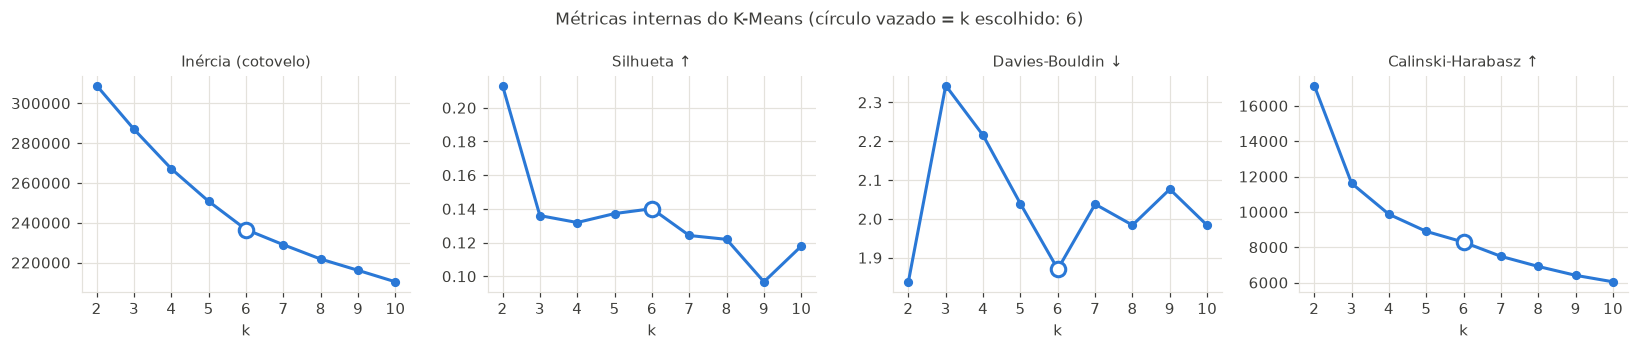

In [3]:
por_k = pd.DataFrame(metricas["metricas_por_k"])
display(por_k)

fig, eixos = plt.subplots(1, 4, figsize=(15, 3.2))
for eixo, (coluna, titulo) in zip(eixos, [
    ("inercia", "Inércia (cotovelo)"),
    ("silhueta", "Silhueta ↑"),
    ("davies_bouldin", "Davies-Bouldin ↓"),
    ("calinski_harabasz", "Calinski-Harabasz ↑"),
]):
    eixo.plot(por_k["k"], por_k[coluna], color=AZUL, linewidth=2, marker="o", markersize=5)
    escolhido = por_k.loc[por_k["k"] == metricas["k_escolhido"], coluna].iloc[0]
    eixo.scatter([metricas["k_escolhido"]], [escolhido], s=90, facecolor="white", edgecolor=AZUL, linewidth=2, zorder=3)
    eixo.set_title(titulo, fontsize=10)
    eixo.set_xlabel("k")
    eixo.set_xticks(por_k["k"])
fig.suptitle(f"Métricas internas do K-Means (círculo vazado = k escolhido: {metricas['k_escolhido']})", fontsize=11, color=CINZA_TEXTO)
fig.tight_layout()
plt.show()

**Leitura:**

- A silhueta é **baixa em todos os valores de k** (entre 0,10 e 0,21). Isso indica que as escolas **não formam grupos naturalmente separados**: os perfis variam de forma contínua. Os grupos devem ser lidos como uma **tipologia** — uma partição útil para definir pares comparáveis — e não como "tipos naturais" de escola.
- **k = 2** tem a maior silhueta, mas só separa escolas "com mais recursos" de escolas "com menos recursos", o que é pouco útil para o gestor.
- Entre k = 3 e k = 8, **k = 6** combina a melhor silhueta, um dos menores Davies-Bouldin e grupos interpretáveis (seção 4), com o menor grupo ainda grande (mais de 3.500 escolas-ano).

## 3. Estabilidade e comparação com outros algoritmos

In [4]:
estab = metricas["estabilidade"]
print("ARI entre sementes:      ", estab["ari_entre_sementes"])
print("ARI entre reamostragens: ", estab["ari_entre_reamostragens"])
print("ARI entre anos:          ", estab["ari_entre_anos"])
print("ARI StandardScaler × RobustScaler:", metricas["ari_standard_vs_robust"])
print("Ward (amostra):    ", metricas["comparacao_algoritmos"]["ward"])
print("HDBSCAN (amostra): ", metricas["comparacao_algoritmos"]["hdbscan"])

ARI entre sementes:       [0.9983, 0.9993, 0.9987]
ARI entre reamostragens:  [0.9848, 0.9792, 0.9837]
ARI entre anos:           {'2019->2021': 0.6067, '2019->2023': 0.8534, '2021->2023': 0.5432}
ARI StandardScaler × RobustScaler: 0.5215
Ward (amostra):     {'silhueta': 0.0524, 'ari_com_kmeans': 0.3209}
HDBSCAN (amostra):  {'min_cluster_size': 100, 'grupos': 2, 'fracao_ruido': 0.0492}


**Leitura:**

- **Sementes e reamostragens (ARI ≥ 0,98):** a partição é praticamente a mesma, independentemente da inicialização ou da amostra. O resultado não é obra do acaso.
- **Entre anos (ARI de 0,54 a 0,85):** 2019 e 2023 produzem grupos parecidos (0,85), mas os pares com 2021 são menos estáveis. A diferença vem principalmente do grupo com apoio multiprofissional (seção 4): a presença de nutricionistas caiu de 21% das escolas em 2019 para 13% em 2021, e a de psicólogos subiu de 5% em 2021 para 11% em 2023. Por isso a fronteira desse grupo muda de um ano para outro. Com a tipologia ajustada nos três anos juntos, como aqui, cada escola é comparada com a mesma régua.
- **StandardScaler × RobustScaler (ARI ≈ 0,52):** sensibilidade moderada. A diferença vem principalmente das variáveis binárias raras: o `RobustScaler` usa o intervalo interquartil, que é zero para binárias com menos de 25% de valores 1, e essas colunas deixam de ser reescaladas. O `StandardScaler`, combinado com a remoção das quase constantes, trata todas as colunas de forma homogênea e foi mantido.
- **Ward (ARI ≈ 0,32) e HDBSCAN:** o HDBSCAN encontra só duas regiões densas, separadas basicamente pela presença de psicólogo. O restante do espaço não tem fronteiras naturais, o que confirma a leitura das métricas. O K-Means é adequado aqui justamente porque particiona o espaço mesmo sem fronteiras naturais.

## 4. Perfil dos grupos

In [5]:
NOMES = {
    0: "Recursos mínimos",
    1: "Espaços sem tecnologia",
    2: "Materiais sem tecnologia",
    3: "Apoio multiprofissional",
    4: "Tecnologia sem espaços",
    5: "Estrutura completa",
}
ROTULOS = [f"{c} · {NOMES[c]}" for c in perfis.index]

resumo = pd.DataFrame({
    "grupo": [NOMES[c] for c in perfis.index],
    "escolas-ano": perfis["escolas_ano"],
    "% do total": 100 * perfis["escolas_ano"] / perfis["escolas_ano"].sum(),
    "matrícula mediana": perfis["matricula_mediana"],
    "% rural": 100 * perfis["prop_localizacao_rural"],
    "% estadual": 100 * perfis["prop_rede_estadual"],
    "% oferece médio": 100 * perfis["media_oferece_medio"],
})
display(resumo)

,grupo,escolas-ano,% do total,matrícula mediana,% rural,% estadual,% oferece médio
cluster,,,,,,,
0,Recursos mínimos,19488,31.27,191.00,59.63,6.97,4.78
1,Espaços sem tecnologia,9850,15.80,397.00,24.06,20.89,15.40
2,Materiais sem tecnologia,9080,14.57,296.00,37.30,10.08,5.10
3,Apoio multiprofissional,4298,6.90,267.00,38.95,2.05,1.63
4,Tecnologia sem espaços,10499,16.85,285.00,32.18,27.14,18.37
5,Estrutura completa,9110,14.62,483.00,9.39,63.10,57.45


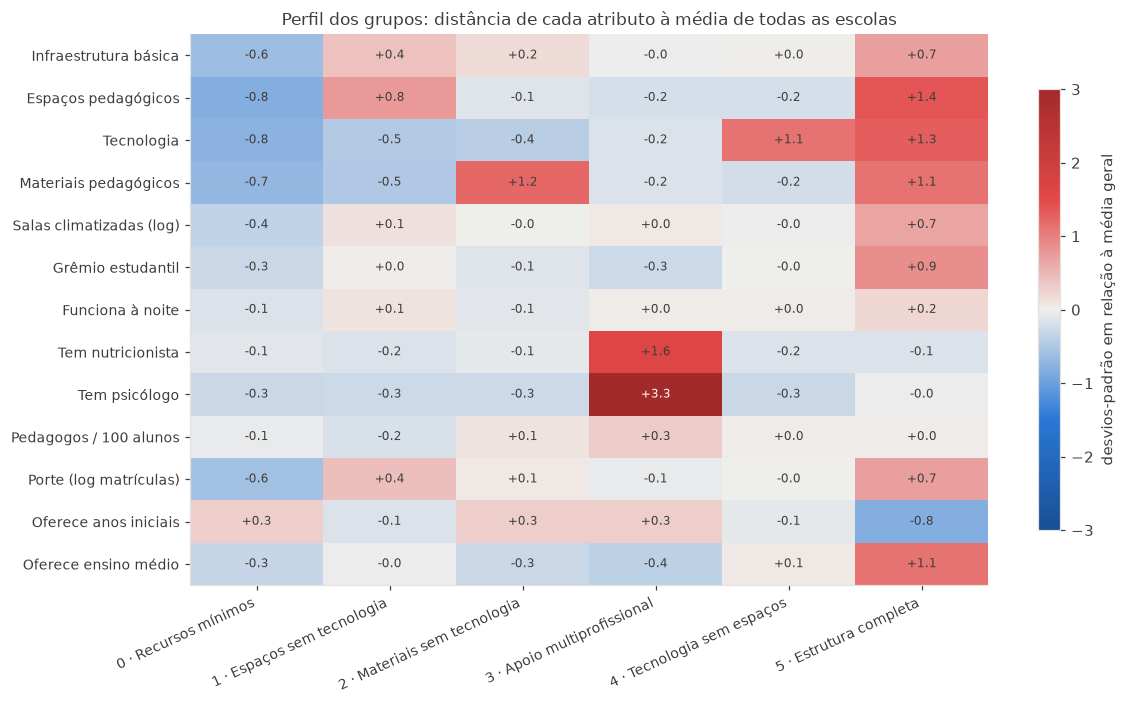

In [6]:
destaques = {
    "media_indice_infraestrutura_basica": "Infraestrutura básica",
    "media_indice_espacos_pedagogicos": "Espaços pedagógicos",
    "media_indice_tecnologia": "Tecnologia",
    "media_indice_materiais": "Materiais pedagógicos",
    "media_salas_climatizadas_log": "Salas climatizadas (log)",
    "media_orgao_gremio_estudantil": "Grêmio estudantil",
    "media_noturno": "Funciona à noite",
    "media_tem_nutricionista": "Tem nutricionista",
    "media_tem_psicologo": "Tem psicólogo",
    "media_profissional_pedagogia_100_alunos": "Pedagogos / 100 alunos",
    "media_porte_log": "Porte (log matrículas)",
    "media_oferece_iniciais": "Oferece anos iniciais",
    "media_oferece_medio": "Oferece ensino médio",
}
geral = matriz[[c.removeprefix("media_") for c in destaques]].agg(["mean", "std"])
z = pd.DataFrame({
    rotulo: (perfis[coluna] - geral.loc["mean", coluna.removeprefix("media_")]) / geral.loc["std", coluna.removeprefix("media_")]
    for coluna, rotulo in destaques.items()
}).T
z.columns = ROTULOS

# Escala divergente: azul (abaixo da média) — cinza neutro — vermelho (acima da média).
divergente = LinearSegmentedColormap.from_list("divergente", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a32a2a"])
limite = np.ceil(z.abs().clip(upper=3).max().max())

fig, eixo = plt.subplots(figsize=(11, 6.5))
imagem = eixo.imshow(z.clip(-limite, limite), cmap=divergente, vmin=-limite, vmax=limite, aspect="auto")
eixo.set_xticks(range(len(z.columns)), z.columns, rotation=25, ha="right", fontsize=9)
eixo.set_yticks(range(len(z.index)), z.index, fontsize=9)
eixo.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        valor = z.iat[i, j]
        eixo.text(j, i, f"{valor:+.1f}", ha="center", va="center", fontsize=8,
                  color="white" if abs(valor) > 0.6 * limite else CINZA_TEXTO)
barra = fig.colorbar(imagem, ax=eixo, shrink=0.8)
barra.set_label("desvios-padrão em relação à média geral")
eixo.set_title("Perfil dos grupos: distância de cada atributo à média de todas as escolas", fontsize=11)
fig.tight_layout()
plt.show()

In [7]:
pd.DataFrame(metricas["descricao_grupos"]).T

,acima_da_media,abaixo_da_media
0,"{'oferece_iniciais': 0.29, 'prop_raca_nao_decl...","{'indice_espacos_pedagogicos': -0.81, 'indice_..."
1,"{'indice_espacos_pedagogicos': 0.76, 'porte_lo...","{'indice_materiais': -0.48, 'indice_tecnologia..."
2,"{'indice_materiais': 1.2, 'oferece_iniciais': ...","{'indice_tecnologia': -0.41, 'oferece_medio': ..."
3,"{'tem_psicologo': 3.31, 'tem_nutricionista': 1...","{'oferece_medio': -0.4, 'orgao_gremio_estudant..."
4,"{'indice_tecnologia': 1.12, 'prop_raca_branca'...","{'tem_psicologo': -0.29, 'indice_materiais': -..."
5,"{'indice_espacos_pedagogicos': 1.37, 'indice_t...","{'oferece_iniciais': -0.8, 'prop_raca_nao_decl..."


**Interpretação dos grupos** (os nomes são uma proposta para discussão):

| Grupo | Nome | Perfil |
| --- | --- | --- |
| 0 | Recursos mínimos | O maior grupo (31%). Escolas pequenas, majoritariamente municipais e rurais, com os menores índices de espaços pedagógicos, tecnologia e materiais. Concentram-se nos anos iniciais. |
| 1 | Espaços sem tecnologia | Escolas maiores e urbanas, com biblioteca, sala de leitura e quadra, mas com pouca tecnologia e poucos materiais. |
| 2 | Materiais sem tecnologia | Escolas municipais com o maior índice de materiais pedagógicos, mas pouca tecnologia. |
| 3 | Apoio multiprofissional | Todas têm psicólogo e 78% têm nutricionista; nas demais dimensões ficam próximas da média. Quase todas municipais (98%). O grupo cresce em 2023, acompanhando o aumento da presença de psicólogos nas redes. |
| 4 | Tecnologia sem espaços | Escolas com computadores e internet para os alunos, mas com poucos espaços pedagógicos e materiais. |
| 5 | Estrutura completa | Escolas maiores, urbanas e majoritariamente estaduais, com os maiores índices em todas as dimensões, grêmio estudantil e ensino médio. |

## 5. IDEB por grupo e etapa

O IDEB não entrou no agrupamento. Aqui ele é ligado de volta a cada etapa pela tabela `ligacao_etapas.csv` e comparado **dentro de cada etapa**, já que os valores não são comparáveis entre etapas.

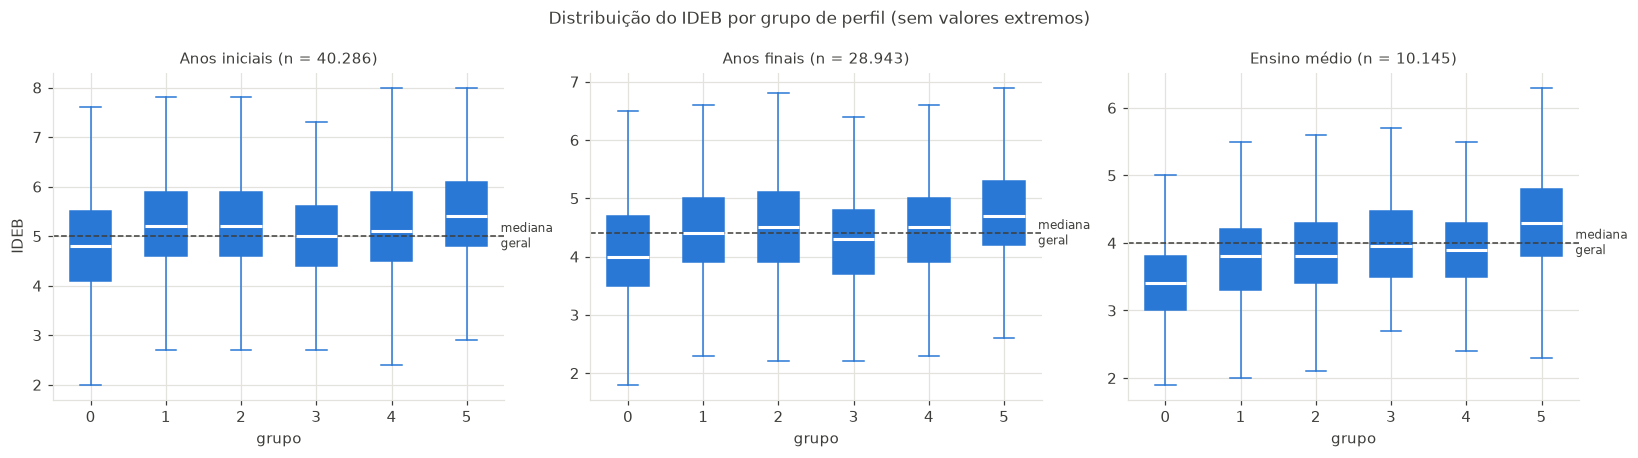

anos_escolares,Anos finais,Anos iniciais,Ensino médio
0 · Recursos mínimos,4.00,4.80,3.40
1 · Espaços sem tecnologia,4.40,5.20,3.80
2 · Materiais sem tecnologia,4.50,5.20,3.80
3 · Apoio multiprofissional,4.30,5.00,3.95
4 · Tecnologia sem espaços,4.50,5.10,3.90
5 · Estrutura completa,4.70,5.40,4.30


In [8]:
ideb = ligacao.merge(atribuicoes, on=["id_escola", "ano"], validate="many_to_one")
ETAPAS = {"iniciais (1-5)": "Anos iniciais", "finais (6-9)": "Anos finais", "todos (1-4)": "Ensino médio"}

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for eixo, (etapa, titulo) in zip(eixos, ETAPAS.items()):
    dados = ideb[ideb["anos_escolares"] == etapa]
    grupos = [dados.loc[dados["cluster"] == c, "ideb"].dropna() for c in perfis.index]
    caixas = eixo.boxplot(
        grupos, tick_labels=[str(c) for c in perfis.index], widths=0.55, patch_artist=True,
        showfliers=False, medianprops={"color": "white", "linewidth": 2},
        boxprops={"facecolor": AZUL, "edgecolor": AZUL},
        whiskerprops={"color": AZUL}, capprops={"color": AZUL},
    )
    geral_etapa = dados["ideb"].median()
    eixo.axhline(geral_etapa, color=CINZA_TEXTO, linewidth=1, linestyle="--")
    eixo.text(len(grupos) + 0.45, geral_etapa, "mediana\ngeral", fontsize=8, va="center", color=CINZA_TEXTO)
    eixo.set_title(f"{titulo} (n = {len(dados):,})".replace(",", "."), fontsize=10)
    eixo.set_xlabel("grupo")
eixos[0].set_ylabel("IDEB")
fig.suptitle("Distribuição do IDEB por grupo de perfil (sem valores extremos)", fontsize=11, color=CINZA_TEXTO)
fig.tight_layout()
plt.show()

tabela = ideb.groupby(["cluster", "anos_escolares"])["ideb"].median().unstack().rename(columns=ETAPAS)
tabela.index = ROTULOS
tabela

**Leitura:**

- O IDEB acompanha o nível de recursos: o grupo **0 (recursos mínimos)** tem as menores medianas em todas as etapas, e o grupo **5 (estrutura completa)** as maiores.
- Os grupos intermediários (1 a 4) têm IDEB parecido entre si, apesar de perfis diferentes: ter tecnologia, espaços, materiais ou apoio multiprofissional isoladamente se associa a resultados semelhantes.
- **Associação não é causa:** os grupos também diferem em rede, localização e porte, que afetam ao mesmo tempo a infraestrutura e o IDEB.
- A dispersão **dentro** de cada grupo é grande. É essa dispersão que a próxima funcionalidade — detecção de anomalias — vai explorar: escolas com IDEB muito abaixo dos pares do mesmo grupo e da mesma etapa.

## 6. Composição dos grupos e escolas imputadas

In [9]:
composicao = perfis[["prop_rede_municipal", "prop_rede_estadual", "prop_localizacao_rural", "prop_ano_2019", "prop_ano_2021", "prop_ano_2023", "prop_materiais_imputados", "prop_gremio_imputado"]].mul(100)
composicao.index = ROTULOS
composicao.columns = ["% municipal", "% estadual", "% rural", "% 2019", "% 2021", "% 2023", "% materiais imputados", "% grêmio imputado"]
composicao

,% municipal,% estadual,% rural,% 2019,% 2021,% 2023,% materiais imputados,% grêmio imputado
0 · Recursos mínimos,93.03,6.97,59.63,38.91,29.84,31.26,6.19,1.09
1 · Espaços sem tecnologia,79.10,20.89,24.06,36.73,26.92,36.35,3.86,1.11
2 · Materiais sem tecnologia,89.91,10.08,37.30,34.74,29.07,36.19,1.53,0.57
3 · Apoio multiprofissional,97.93,2.05,38.95,34.67,18.31,47.02,2.82,0.37
4 · Tecnologia sem espaços,72.81,27.14,32.18,35.15,30.30,34.56,2.00,0.44
5 · Estrutura completa,35.53,63.10,9.39,30.49,26.31,43.19,0.49,0.50


- Os anos se distribuem de forma equilibrada entre os grupos: nenhum grupo é "de um ano só".
- O grupo 3 (apoio multiprofissional) é o único com distribuição desigual entre os anos: tem menos escolas de 2021 e mais de 2023.
- As escolas com materiais imputados representam no máximo 6% de um grupo (grupo 0) e não determinam nenhum deles.

## 7. Próximos passos

- Usar os grupos como **pares** na detecção de anomalias: IDEB e evolução entre edições comparados dentro de grupo × etapa.
- Revisar os nomes dos grupos com base no conhecimento do domínio.